In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


In [6]:
df= pd.read_csv(r"C:\Users\mahesh\Downloads\creditcard.csv.zip")
print(df.head())


   Time        V1        V2        V3        V4        V5        V6        V7  \
0   0.0 -1.359807 -0.072781  2.536347  1.378155 -0.338321  0.462388  0.239599   
1   0.0  1.191857  0.266151  0.166480  0.448154  0.060018 -0.082361 -0.078803   
2   1.0 -1.358354 -1.340163  1.773209  0.379780 -0.503198  1.800499  0.791461   
3   1.0 -0.966272 -0.185226  1.792993 -0.863291 -0.010309  1.247203  0.237609   
4   2.0 -1.158233  0.877737  1.548718  0.403034 -0.407193  0.095921  0.592941   

         V8        V9  ...       V21       V22       V23       V24       V25  \
0  0.098698  0.363787  ... -0.018307  0.277838 -0.110474  0.066928  0.128539   
1  0.085102 -0.255425  ... -0.225775 -0.638672  0.101288 -0.339846  0.167170   
2  0.247676 -1.514654  ...  0.247998  0.771679  0.909412 -0.689281 -0.327642   
3  0.377436 -1.387024  ... -0.108300  0.005274 -0.190321 -1.175575  0.647376   
4 -0.270533  0.817739  ... -0.009431  0.798278 -0.137458  0.141267 -0.206010   

        V26       V27       V28 

In [7]:
print("/*********************************/")
print(df.info())
print(df.describe())
print(df.isnull().sum())

/*********************************/
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     2848

In [11]:
print(df.columns)
df.shape

Index(['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10',
       'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20',
       'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount',
       'Class'],
      dtype='object')


(284807, 31)

<Axes: xlabel='Class', ylabel='count'>

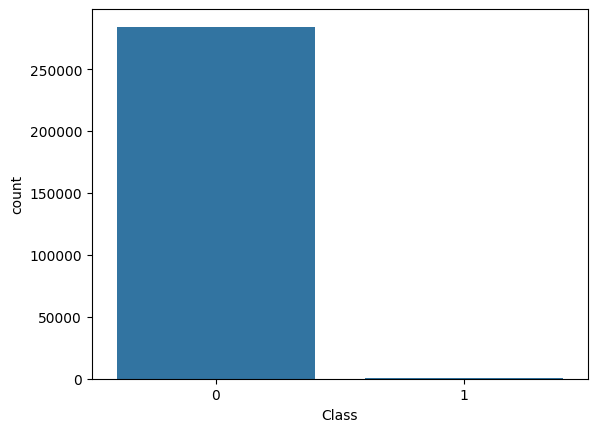

In [12]:
import seaborn as sns

sns.countplot(x='Class',data=df)

<Axes: xlabel='Time'>

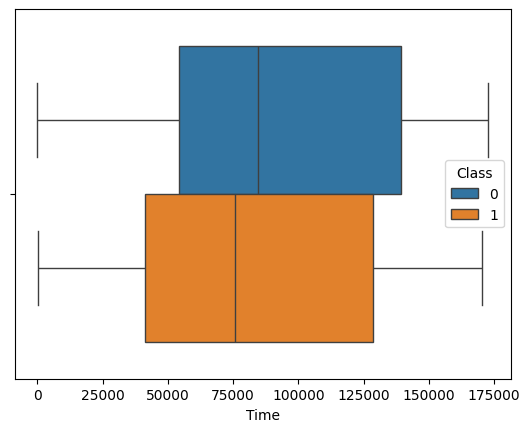

In [21]:
sns.boxplot(x='Time',hue='Class',data=df)

In [23]:
df_clean=df.drop_duplicates()

In [24]:
df.shape

(284807, 31)

In [25]:
x=df_clean[['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10',
       'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20',
       'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount']]

In [ ]:
from sklearn.model_selection import cross_val_score
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
# 1. K-Nearest Neighbors (KNN)
from sklearn.neighbors import KNeighborsClassifier

# 2. Support Vector Machine (SVM)
from sklearn.svm import SVC

# 3. Decision Tree
from sklearn.tree import DecisionTreeClassifier

# 4. Naive Bayes (Gaussian variant is the most common)
from sklearn.naive_bayes import GaussianNB




In [34]:
models ={
    "linear_model":LogisticRegression(),
    "random_forest":RandomForestClassifier(),
    "knn":KNeighborsClassifier(),
    "svm":SVC(),
    "decision_tree":DecisionTreeClassifier(),
    "naive_bayes":GaussianNB(),

}
import warnings
warnings.filterwarnings("ignore")

from sklearn.model_selection import cross_validate

# 1. Initialize your results dictionary exactly as you planned
res = {
    "name": [],
    "scores": [],       # This will hold the default cross_val_score (Accuracy)
    "F1_score": [],
    "precision": [],
    "recall": [],
    "accuracy": []
}

# 2. Define the scoring metrics you want to extract
# Note: If your dataset is highly imbalanced, change 'macro' to 'weighted'
scoring_metrics = ['accuracy', 'precision_macro', 'recall_macro', 'f1_macro']

# 3. Loop through your models dictionary
for name, model in models.items():
    # Run cross_validate to get all metrics simultaneously
    cv_results = cross_validate(model, x, df_clean['Class'], cv=5, scoring=scoring_metrics)
    
    # Append the averaged results into your dictionary
    res['name'].append(name)
    res['scores'].append(cv_results['test_accuracy'].mean()) # Traditional cross_val_score default
    res['accuracy'].append(cv_results['test_accuracy'].mean())
    res['precision'].append(cv_results['test_precision_macro'].mean())
    res['recall'].append(cv_results['test_recall_macro'].mean())
    res['F1_score'].append(cv_results['test_f1_macro'].mean())



In [35]:
df_results = pd.DataFrame(res)
print(df_results)


            name    scores  F1_score  precision    recall  accuracy
0   linear_model  0.995749  0.766378   0.859724  0.804857  0.995749
1  random_forest  0.800849  0.727190   0.876956  0.788239  0.800849
2            knn  0.448237  0.275677   0.499096  0.385757  0.448237
3            svm  0.998333  0.499583   0.499166  0.500000  0.998333
4  decision_tree  0.799722  0.646771   0.742621  0.760329  0.799722
5    naive_bayes  0.992394  0.608603   0.567078  0.822830  0.992394


In [37]:
from sklearn.model_selection import RandomizedSearchCV

param_LR ={
    'C':[0.01, 0.1, 1, 10, 100],
    'penalty':['l1','l2'],
    'solver':['liblinear','saga'],
    'max_iter':[1000]
}

lr_random = RandomizedSearchCV(
    estimator = LogisticRegression(),
    param_distributions=param_LR,
    n_iter=10,
    scoring ='f1_macro',
    cv=3,
    n_jobs=-1,
    random_state=42
)

print("Tuning Logistic Regression ...")
lr_random.fit(x, df_clean['Class'])
print("Best parameter found:",lr_random.best_params_)
print("best f1 score found",lr_random.best_score_)



Tuning Logistic Regression ...
Best parameter found: {'solver': 'liblinear', 'penalty': 'l1', 'max_iter': 1000, 'C': 1}
best f1 score found 0.824125195589437


In [40]:
print(x.shape)
print(df_clean['Class'].shape)

(283726, 30)
(283726,)


In [41]:
param_RF={
    'n_estimators': [100],
    'max_depth': [None, 10, 20],
    'min_samples_split':[2,5],
    'min_samples_leaf':[1,2,4],
    'bootstrap':[True,False],
    'class_weight':['balanced',None]
}

rf_random = RandomizedSearchCV(
    estimator = RandomForestClassifier(),
    param_distributions = param_RF,
    n_iter=10,
    scoring='f1_macro',
    cv=3,
    n_jobs=-1,
    random_state=42
)
print("Tuning Random Forest (This will take a few minutes)...")
rf_random.fit(x,df_clean['Class'])
print("Best parameter found:",rf_random.best_params_)
print("best f1 score found",rf_random.best_score_)


Tuning Random Forest (This will take a few minutes)...
Best parameter found: {'n_estimators': 100, 'min_samples_split': 2, 'min_samples_leaf': 4, 'max_depth': 10, 'class_weight': 'balanced', 'bootstrap': True}
best f1 score found 0.8726323378244439


In [42]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()

x_scaler = scaler.fit_transform(x)

new_model_knn = cross_validate(KNeighborsClassifier(),x_scaler,df_clean['Class'],cv = 5,scoring = scoring_metrics)

print("KNN with Standard Scaler Results:")
print("accaracy:",new_model_knn['test_accuracy'].mean())
print("precision:",new_model_knn['test_precision_macro'].mean())
print("recall:",new_model_knn['test_recall_macro'].mean())
print("f1 score:",new_model_knn['test_f1_macro'].mean())

KNN with Standard Scaler Results:
accaracy: 0.9993021445739053
precision: 0.9283654837052653
recall: 0.86443410701226
f1 score: 0.8893721036780124


In [ ]:
new_model_svm = cross_validate(SVC(),x_scaler,df_clean['Class'],cv=5,scoring=scoring_metrics)
print("SVM with Standard Scaler Results:")
print("accaracy:",new_model_svm['test_accuracy'].mean())
print("precision:",new_model_svm['test_precision_macro'].mean())
print("recall:",new_model_svm['test_recall_macro'].mean())
print("f1 score:",new_model_svm['test_f1_macro'].mean())


SVM with Standard Scaler Results:
accaracy: 0.9989391183608205
precision: 0.941525956873728
recall: 0.7125467936057395
f1 score: 0.7829139348726185


In [47]:
final_LR = LogisticRegression(solver='liblinear', penalty='l1', max_iter=1000, C=1)
final_RF = RandomForestClassifier(n_estimators=100, min_samples_split=2, min_samples_leaf=4, max_depth=10, class_weight='balanced', bootstrap=True)
final_KNN = KNeighborsClassifier()
from sklearn.ensemble import StackingClassifier
from sklearn.pipeline import make_pipeline

base_estimators = [
    ('knn',make_pipeline(StandardScaler(),final_KNN)),
    ('rf',final_RF),
    ('Lr_base',final_LR)
]

final_estimator = final_LR

stacking_model = StackingClassifier(
    estimators=base_estimators,
    final_estimator=final_estimator,
    cv=5,
    n_jobs=-1,
    
)

final_model_results = cross_validate(stacking_model,x,df_clean['Class'],cv = 3,scoring = scoring_metrics)
print("Stacking Model Results:")
print("accaracy:",final_model_results['test_accuracy'].mean())
print("precision:",final_model_results['test_precision_macro'].mean())
print("recall:",final_model_results['test_recall_macro'].mean())
print("f1 score:",final_model_results['test_f1_macro'].mean())




Stacking Model Results:
accaracy: 0.9992246037087953
precision: 0.9432649523004225
recall: 0.8233429785458096
f1 score: 0.8621516363432161


In [48]:
from sklearn.ensemble import AdaBoostClassifier
final_adaboost = AdaBoostClassifier(n_estimators = 100, random_state = 42)
final_adaboost_results = cross_validate(final_adaboost,x,df_clean['Class'],cv=3,scoring = scoring_metrics)
print("AdaBoost Results:")
print("accaracy:",final_adaboost_results['test_accuracy'].mean())
print("precision:",final_adaboost_results['test_precision_macro'].mean())
print("recall:",final_adaboost_results['test_recall_macro'].mean())
print("f1 score:",final_adaboost_results['test_f1_macro'].mean())



AdaBoost Results:
accaracy: 0.9887286336525349
precision: 0.7827483626428261
recall: 0.796977438378638
f1 score: 0.6953107622251972


In [49]:
from sklearn.ensemble import GradientBoostingClassifier

final_gradient = GradientBoostingClassifier(n_estimators=10,learning_rate=1,random_state=42)
final_gradient_results = cross_validate(final_gradient,x,df_clean['Class'],cv=3,scoring = scoring_metrics)

print("Gradient Boosting Results:")
print("Accuracy:", final_gradient_results['test_accuracy'].mean())
print("Precision:", final_gradient_results['test_precision_macro'].mean())
print("Recall:", final_gradient_results['test_recall_macro'].mean())
print("F1 Score:", final_gradient_results['test_f1_macro'].mean())

Gradient Boosting Results:
Accuracy: 0.6684253840923086
Precision: 0.716098236531192
Recall: 0.6943701040938892
F1 Score: 0.53485669018134


In [50]:
from xgboost import XGBClassifier

final_xgb = XGBClassifier(n_estimators=10,learning_rate=1,random_state=42,eval_metric ='mlogloss')

final_xgb_results = cross_validate(final_xgb,x,df_clean['Class'],cv=3,scoring = scoring_metrics)
print("XGBoost Results:")
print("Accuracy:", final_xgb_results['test_accuracy'].mean())
print("Precision:", final_xgb_results['test_precision_macro'].mean())
print("Recall:", final_xgb_results['test_recall_macro'].mean())
print("F1 Score:", final_xgb_results['test_f1_macro'].mean())




XGBoost Results:
Accuracy: 0.9953652697704588
Precision: 0.7229853779581851
Recall: 0.8351270915252567
F1 Score: 0.7273285646495374


In [57]:
from sklearn.decomposition import PCA

x_reduced = PCA(n_components = 2).fit_transform(x)



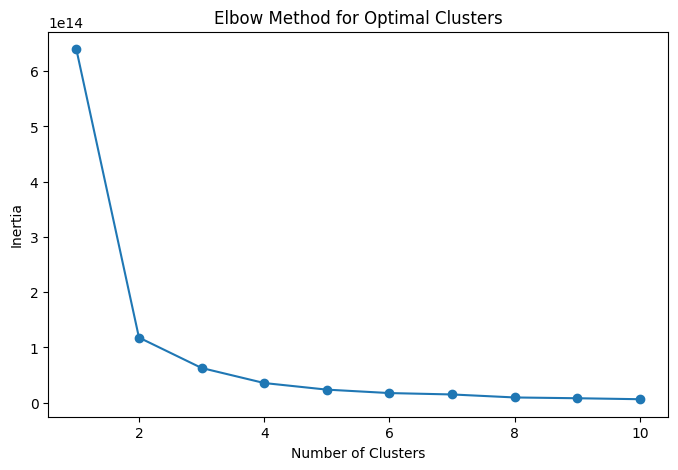

In [58]:
from sklearn.cluster import KMeans

inertial=[]
for i in range(1,11):
    kmeans = KMeans(n_clusters=i,random_state=42)
    kmeans.fit(x_reduced)
    inertial.append(kmeans.inertia_)

plt.figure(figsize=(8,5))
plt.plot(range(1,11),inertial,marker='o')
plt.title("Elbow Method for Optimal Clusters")
plt.xlabel("Number of Clusters")
plt.ylabel("Inertia")
plt.show()

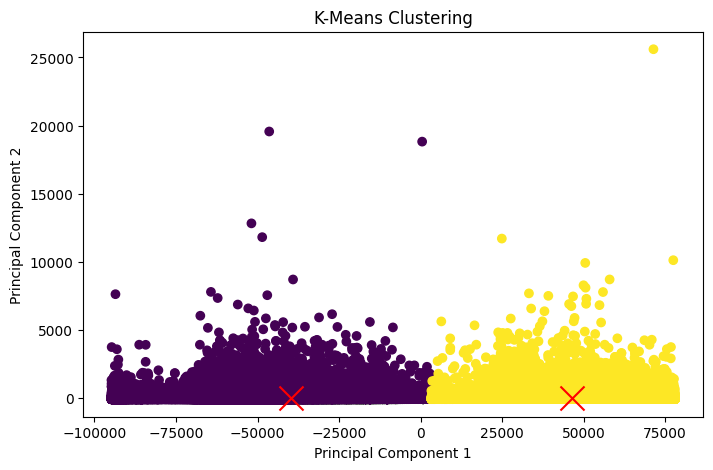

In [61]:

kmeans = KMeans(n_clusters=2,random_state=42)
kmeans.fit(x_reduced)
plt.figure(figsize=(8,5))
plt.scatter(x_reduced[:, 0], x_reduced[:, 1], c=kmeans.labels_, cmap='viridis')
plt.scatter(kmeans.cluster_centers_[:, 0], kmeans.cluster_centers_[:, 1], s=300, c='red', marker='x')
plt.title("K-Means Clustering")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.show()


In [62]:
data = {
    'name': [
        'linear_model', 'random_forest', 'knn', 'svm', 'decision_tree', 
        'naive_bayes', 'stacking_model', 'adaboost', 'gradient_boosting', 'xgboost'
    ],
    'scores': [
        0.995749, 0.800849, 0.999302, 0.998333, 0.799722, 
        0.992394, 0.999225, 0.988729, 0.668425, 0.995365
    ],
    'F1_score': [
        0.824125, 0.872632, 0.889372, 0.499583, 0.646771, 
        0.608603, 0.862152, 0.695311, 0.534857, 0.727329
    ],
    'precision': [
        0.859724, 0.876956, 0.928365, 0.499166, 0.742621, 
        0.567078, 0.943265, 0.782748, 0.716098, 0.722985
    ],
    'recall': [
        0.804857, 0.788239, 0.864434, 0.500000, 0.760329, 
        0.822830, 0.823343, 0.796977, 0.694370, 0.835127
    ],
    'accuracy': [
        0.995749, 0.800849, 0.999302, 0.998333, 0.799722, 
        0.992394, 0.999225, 0.988729, 0.668425, 0.995365
    ]
}

# Construct the DataFrame
df = pd.DataFrame(data)
print(df)

                name    scores  F1_score  precision    recall  accuracy
0       linear_model  0.995749  0.824125   0.859724  0.804857  0.995749
1      random_forest  0.800849  0.872632   0.876956  0.788239  0.800849
2                knn  0.999302  0.889372   0.928365  0.864434  0.999302
3                svm  0.998333  0.499583   0.499166  0.500000  0.998333
4      decision_tree  0.799722  0.646771   0.742621  0.760329  0.799722
5        naive_bayes  0.992394  0.608603   0.567078  0.822830  0.992394
6     stacking_model  0.999225  0.862152   0.943265  0.823343  0.999225
7           adaboost  0.988729  0.695311   0.782748  0.796977  0.988729
8  gradient_boosting  0.668425  0.534857   0.716098  0.694370  0.668425
9            xgboost  0.995365  0.727329   0.722985  0.835127  0.995365


In [64]:
from sklearn.model_selection import cross_validate, StratifiedKFold
knn_pipeline = make_pipeline(
    StandardScaler(),
    KNeighborsClassifier()
)

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

new_model_knn = cross_validate(
    knn_pipeline,
    x,
    df_clean['Class'],
    cv=cv,
    scoring=scoring_metrics,
    n_jobs=-1
)

print("KNN with StandardScaler Results:")
print("Accuracy:", new_model_knn['test_accuracy'].mean())
print("Precision:", new_model_knn['test_precision_macro'].mean())
print("Recall:", new_model_knn['test_recall_macro'].mean())
print("F1 score:", new_model_knn['test_f1_macro'].mean())

KNN with StandardScaler Results:
Accuracy: 0.9994854188943677
Precision: 0.9613353617556658
Recall: 0.8773154649238386
F1 score: 0.9149638225231609


In [65]:
SVM_pipeline = make_pipeline(
    StandardScaler(),
    SVC()
)

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

new_model_svm = cross_validate(
    SVM_pipeline,
    x,
    df_clean['Class'],
    cv=cv,
    scoring=scoring_metrics,
    n_jobs=-1
)

print("svm with StandardScaler Results:")
print("Accuracy:", new_model_svm['test_accuracy'].mean())
print("Precision:", new_model_svm['test_precision_macro'].mean())
print("Recall:", new_model_svm['test_recall_macro'].mean())
print("F1 score:", new_model_svm['test_f1_macro'].mean())

svm with StandardScaler Results:
Accuracy: 0.999369109460001
Precision: 0.975426358514403
Recall: 0.8276313311786225
F1 score: 0.887632589954894


In [66]:
from sklearn.model_selection import cross_validate, StratifiedKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scoring_metrics = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "pr_auc": "average_precision"
}

models = {
    "KNN": make_pipeline(
        StandardScaler(),
        KNeighborsClassifier()
    ),
    "SVM": make_pipeline(
        StandardScaler(),
        SVC()
    )
}

for name, model in models.items():
    results = cross_validate(
        model,
        x,
        df_clean["Class"],
        cv=cv,
        scoring=scoring_metrics,
        n_jobs=-1
    )

    print(f"\n{name}")
    print(f"Accuracy:  {results['test_accuracy'].mean():.5f}")
    print(f"Precision: {results['test_precision'].mean():.5f}")
    print(f"Recall:    {results['test_recall'].mean():.5f}")
    print(f"F1-score:  {results['test_f1'].mean():.5f}")
    print(f"PR-AUC:    {results['test_pr_auc'].mean():.5f}")


KNN
Accuracy:  0.99949
Precision: 0.92308
Recall:    0.75474
F1-score:  0.83019
PR-AUC:    0.79516

SVM
Accuracy:  0.99937
Precision: 0.95143
Recall:    0.65532
F1-score:  0.77558
PR-AUC:    0.80274
